In [ ]:
%pip install -q grad-cam segmentation-models-pytorch albumentations transformers torchgeo

In [ ]:
import json, os, zipfile, requests
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from transformers import SegformerForSemanticSegmentation, SegformerConfig
from sklearn.model_selection import train_test_split
from pytorch_grad_cam import SegEigenCAM
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cpu'

In [ ]:
REPO = "williamtheodoruswijaya/PDIS-Net"
REPO_DIR = Path("/content/PDIS-Net")
DATA_DIR = Path("/content/flopwd_data")

if not REPO_DIR.exists():
    !GIT_LFS_SKIP_SMUDGE=1 git clone https://github.com/{REPO} {REPO_DIR}

%cd {REPO_DIR}

ROOT = REPO_DIR
MODEL_DIR = ROOT / "model"
XAI_OUT = ROOT / "xai" / "out"
XAI_OUT.mkdir(parents=True, exist_ok=True)

DATASET_ID = "114xnPVZtthHi4Bejzho33vGJSqb4-F8g"

if not DATA_DIR.exists():
    !gdown {DATASET_ID} -O /content/dataset.zip
    with zipfile.ZipFile("/content/dataset.zip") as z:
        z.extractall("/content/flopwd_data")

DATA = DATA_DIR / "Dal Lake Floating Plastic Waste Detection Dataset (FloPWD 2025)"
assert DATA.exists(), f"Dataset not found at {DATA}"

/content/PDIS-Net


In [ ]:
# RUNS = [
#     "01-segformer-mitb3-raw",
#     "02-segformer-mitb3-imagenet",
#     "03-unet-mitb3-imagenet",
#     "04-segformer-mitb3-aerial",
#     "05-segformer-mitb3-ade",
#     "06-segformer-mitb3-drone",
#     "07-segformer-mitb5-imagenet",
#     "08-unet-resnet34-raw",
#     "09-unet-resnet34-imagenet",
#     "10-segformer-resnet34-imagenet",
#     "11-segformer-resnet34-raw",
#     "12-segformer-mitb0-imagenet",
#     "13-deeplabv3plus-mitb3-imagenet",
#     "14-deeplabv3plus-resnet34-imagenet",
#     "15-deeplabv3plus-resnet34-raw",
#     "16-deeplab-resnet50-imagenet-v1",
#     "17-deeplab-resnet101-imagenet",
# ]

RUNS = [
    "02-segformer-mitb3-imagenet",
]

CUSTOM_PTH = {
    "03-unet-mitb3-imagenet": "UNET_MITB3 Model.pth",
}

SAMPLES = ["img1484.jpg", "img324.jpg", "img2.jpg", "img563.jpg"]
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

CUSTOM_PTH = {
    "03-unet-mitb3-imagenet": "UNET_MITB3 Model.pth",
}

SAMPLES = ["img1484.jpg", "img324.jpg", "img2.jpg", "img563.jpg"]
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

In [ ]:
def resolve_run_paths(run):
    base = MODEL_DIR / run
    pth_name = CUSTOM_PTH.get(run, "best.pth")

    for version in ["v1", "v2", "v3"]:
        vdir = base / version
        pth = vdir / pth_name
        metrics = vdir / "test_metrics.json"
        if pth.exists() and metrics.exists():
            return vdir, pth, metrics

    pth = base / pth_name
    metrics = base / "test_metrics.json"
    if pth.exists() and metrics.exists():
        return base, pth, metrics

    return None, None, None

In [ ]:
def find_remote_path(run):
    pth_name = CUSTOM_PTH.get(run, "best.pth")
    pth_name_e = pth_name.replace(" ", "%20")
    for version in ["v1", "v2", "v3"]:
        url = f"https://media.githubusercontent.com/media/{REPO}/main/model/{run}/{version}/{pth_name_e}"
        if requests.head(url).status_code == 200:
            return f"model/{run}/{version}/{pth_name}", MODEL_DIR / run / version / pth_name
    url = f"https://media.githubusercontent.com/media/{REPO}/main/model/{run}/{pth_name_e}"
    if requests.head(url).status_code == 200:
        return f"model/{run}/{pth_name}", MODEL_DIR / run / pth_name
    return None, None


def download_lfs(filepath, save_path):
    url = f"https://media.githubusercontent.com/media/{REPO}/main/{filepath.replace(' ', '%20')}"
    r = requests.get(url, stream=True)
    if r.status_code == 200:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        with open(save_path, "wb") as f:
            for chunk in r.iter_content(8192):
                f.write(chunk)
        print(f"✅ {filepath} ({save_path.stat().st_size/1e6:.1f} MB)")
    else:
        print(f"❌ {filepath} — HTTP {r.status_code}")


def download_metrics(run, save_dir):
    metrics_path = save_dir / "test_metrics.json"
    if metrics_path.exists():
        return True
    for version in ["v1", "v2", "v3", ""]:
        remote_metrics_path = f"model/{run}/{version}/test_metrics.json" if version else f"model/{run}/test_metrics.json"
        url = f"https://raw.githubusercontent.com/{REPO}/main/{remote_metrics_path}"
        r = requests.get(url)
        if r.status_code == 200:
            metrics_path.parent.mkdir(parents=True, exist_ok=True)
            metrics_path.write_text(r.text)
            print(f"✅ metrics {remote_metrics_path}")
            return True
    print(f"❌ metrics not found: {run}")
    return False


for run in RUNS:
    _, pth, _ = resolve_run_paths(run)
    if pth is not None and pth.exists() and pth.stat().st_size > 1e6:
        print(f"⏭️  skip weights {run}")
        pth_dir = pth.parent
    else:
        remote_path, save_path = find_remote_path(run)
        if remote_path is None:
            print(f"❌ {run} — weights not found remotely")
            continue
        download_lfs(remote_path, save_path)
        pth_dir = save_path.parent

    download_metrics(run, pth_dir)

⏭️  skip weights 01-segformer-mitb3-raw
⏭️  skip weights 02-segformer-mitb3-imagenet
⏭️  skip weights 03-unet-mitb3-imagenet
⏭️  skip weights 04-segformer-mitb3-aerial
⏭️  skip weights 05-segformer-mitb3-ade
⏭️  skip weights 06-segformer-mitb3-drone
⏭️  skip weights 07-segformer-mitb5-imagenet
⏭️  skip weights 08-unet-resnet34-raw
⏭️  skip weights 09-unet-resnet34-imagenet
⏭️  skip weights 10-segformer-resnet34-imagenet
⏭️  skip weights 11-segformer-resnet34-raw
⏭️  skip weights 12-segformer-mitb0-imagenet
⏭️  skip weights 13-deeplabv3plus-mitb3-imagenet
⏭️  skip weights 14-deeplabv3plus-resnet34-imagenet
⏭️  skip weights 15-deeplabv3plus-resnet34-raw
⏭️  skip weights 16-deeplab-resnet50-imagenet-v1
⏭️  skip weights 17-deeplab-resnet101-imagenet


In [ ]:
print("Checking weights...\n")
missing = []
for run in RUNS:
    _, pth, metrics_path = resolve_run_paths(run)
    if pth is None or not pth.exists():
        print(f"❌ NOT FOUND : {run} (weights)")
        missing.append(run)
        continue
    if metrics_path is None or not metrics_path.exists():
        print(f"❌ NOT FOUND : {run} (metrics)")
        missing.append(run)
        continue
    size_mb = pth.stat().st_size / 1e6
    status = "✅" if size_mb > 1 else "⚠️  pointer"
    print(f"{status} {size_mb:7.1f} MB : {run}")
print(f"\n{len(missing)} missing, {len(RUNS)-len(missing)} found")

Checking weights...

✅   189.1 MB : 01-segformer-mitb3-raw
✅   189.1 MB : 02-segformer-mitb3-imagenet
✅   189.6 MB : 03-unet-mitb3-imagenet
✅   189.1 MB : 04-segformer-mitb3-aerial
✅   189.1 MB : 05-segformer-mitb3-ade
✅   189.1 MB : 06-segformer-mitb3-drone
✅   338.8 MB : 07-segformer-mitb5-imagenet
✅    97.9 MB : 08-unet-resnet34-raw
✅    97.9 MB : 09-unet-resnet34-imagenet
✅   100.3 MB : 10-segformer-resnet34-imagenet
✅   100.3 MB : 11-segformer-resnet34-raw
✅    14.9 MB : 12-segformer-mitb0-imagenet
✅   181.1 MB : 13-deeplabv3plus-mitb3-imagenet
✅    89.9 MB : 14-deeplabv3plus-resnet34-imagenet
✅    89.9 MB : 15-deeplabv3plus-resnet34-raw
✅   107.0 MB : 16-deeplab-resnet50-imagenet-v1
✅   183.3 MB : 17-deeplab-resnet101-imagenet

0 missing, 17 found


In [ ]:
labels_df = pd.read_csv(DATA / "Image_labels_Binary Classification Task.csv").rename(columns={
    "image name": "image_name",
    "Presence of plastic waste?": "presence"
})
reg_df = pd.read_csv(DATA / "Mask_foreground_percentages_Regression Task.csv").rename(columns={
    "image name": "image_name",
    "plastic waste accumulation (in percentage)": "fg_pct"
})

df = labels_df.merge(reg_df, on="image_name", how="inner")
df["image_path"] = df["image_name"].apply(lambda x: str(DATA / "Raw_Images" / x))
df["mask_path"] = df["image_name"].str.replace(".jpg", "_mask.png", regex=False).apply(lambda x: str(DATA / "Segmentation_Masks" / x))
df["has_plastic"] = (df["presence"].astype(str).str.lower() == "yes").astype(int)

In [ ]:
def build_model(arch, backbone, init):
    backbone_hf = backbone.replace("_", "-")
    backbone_smp = backbone.replace("-", "_")

    if arch == "segformer":
        src_map = {
            "raw": None,
            "imagenet": f"nvidia/{backbone_hf}",
            "aerial": "chribark/segformer-b3-finetuned-UAVid",
            "ade": "nvidia/segformer-b3-finetuned-ade-512-512",
            "drone": "chribark/segformer-b3-finetuned-UAVid",
        }
        src = src_map.get(init)
        if src is None:
            cfg = SegformerConfig.from_pretrained(f"nvidia/{backbone_hf}", num_labels=2)
            return SegformerForSemanticSegmentation(cfg)
        return SegformerForSemanticSegmentation.from_pretrained(src, num_labels=2, ignore_mismatched_sizes=True)

    arch_map = {
        "unet": smp.Unet,
        "deeplabv3plus": smp.DeepLabV3Plus,
        "unetpp": smp.UnetPlusPlus,
    }
    if arch not in arch_map:
        raise ValueError(f"Unknown arch: {arch}")
    return arch_map[arch](encoder_name=backbone_smp, encoder_weights=None, classes=2)

In [ ]:
def get_target_layer(net, arch):
    if arch == "segformer":
        return net.decode_head.batch_norm
    if arch in ("unet", "unetpp"):
        return net.decoder.blocks[-1]
    if arch == "deeplabv3plus":
        return net.decoder.aspp
    raise ValueError(f"Unsupported arch: {arch}")

In [ ]:
class Logits(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        if hasattr(out, "logits"):
            return F.interpolate(out.logits, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out


class SegEigenCAMLite(SegEigenCAM):
    def get_cam_image(self, input_tensor, target_layer, targets, activations, grads, eigen_smooth):
        a = (np.abs(grads) * activations)[0]
        X = a.reshape(a.shape[0], -1).T
        X = X - X.mean(axis=0)
        _, _, VT = np.linalg.svd(X, full_matrices=False)
        p = (X @ VT[0]).reshape(a.shape[1:])
        if abs(p.min()) > abs(p.max()):
            p = -p
        return p[None]


def ious(p, t, eps=1e-7):
    tp = (p & t).sum()
    fp = (p & (1 - t)).sum()
    fn = ((1 - p) & t).sum()
    tn = ((1 - p) & (1 - t)).sum()
    return (tp + eps) / (tp + fp + fn + eps), (tn + eps) / (tn + fp + fn + eps)


def load_image(r, S):
    img = cv2.cvtColor(cv2.imread(r["image_path"]), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (S, S))
    gt = (cv2.imread(r["mask_path"], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    gt = cv2.resize(gt, (S, S), interpolation=cv2.INTER_NEAREST)
    x = torch.from_numpy(((img / 255.0 - MEAN) / STD).transpose(2, 0, 1)).float()[None].to(DEVICE)
    return img, gt, x


def predict(model, x, threshold):
    with torch.no_grad():
        return (torch.softmax(model(x), 1)[0, 1] > threshold).cpu().numpy().astype(np.uint8)


def explain(cam, x, mask):
    return cam(x, [SemanticSegmentationTarget(1, mask.astype(np.float32))])[0]


def show_grid(names, title, df, model, cam, S, threshold, out_dir):
    valid = [n for n in names if n in df.image_name.values]
    if not valid:
        return
    fig, ax = plt.subplots(len(valid), 5, figsize=(20, 4 * len(valid)))
    if len(valid) == 1:
        ax = ax[None]
    for i, n in enumerate(valid):
        img, gt, x = load_image(df[df.image_name == n].iloc[0], S)
        pr = predict(model, x, threshold)
        panels = [
            (img, n),
            (gt, f"truth {gt.mean()*100:.2f}%"),
            (pr, f"pred {pr.mean()*100:.2f}%"),
            (show_cam_on_image(img / 255.0, explain(cam, x, pr), use_rgb=True), "why predicted"),
            (show_cam_on_image(img / 255.0, explain(cam, x, gt), use_rgb=True), "what in truth"),
        ]
        for a, (im, t) in zip(ax[i], panels):
            a.imshow(im, cmap="gray")
            a.set_title(t, fontsize=9)
            a.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.savefig(out_dir / f"{title}.png", dpi=90, bbox_inches="tight")
    plt.show()
    plt.close()


def faithfulness(per_img, df, model, cam, S, threshold):
    has = per_img[(per_img.gt_pct > 0) & (per_img.pred_pct > 0)]
    kept_hot, kept_cold = [], []
    for n in has.image_name:
        img, gt, x = load_image(df[df.image_name == n].iloc[0], S)
        pr = predict(model, x, threshold)
        c = explain(cam, x, pr)
        idx = np.flatnonzero(pr)
        if len(idx) < 2:
            continue
        order = idx[np.argsort(c.flat[idx])]
        k = len(idx) // 2
        for chosen, bucket in [(order[len(order)-k:], kept_hot), (order[:k], kept_cold)]:
            x2 = x.clone().flatten(2)
            x2[..., chosen] = 0
            bucket.append(float(predict(model, x2.view_as(x), threshold)[pr == 1].mean()))
    return kept_hot, kept_cold

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.



02-segformer-mitb3-imagenet
  arch=segformer | backbone=mit-b3 | init=imagenet | mIoU=0.821


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  179MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.classifier.weight                           

model.safetensors: reconstructing file:   0%|          |  0.00B /  178MB            

model.safetensors: downloading bytes:           |  0.00B            

  reproduced=0.821 | original=0.821


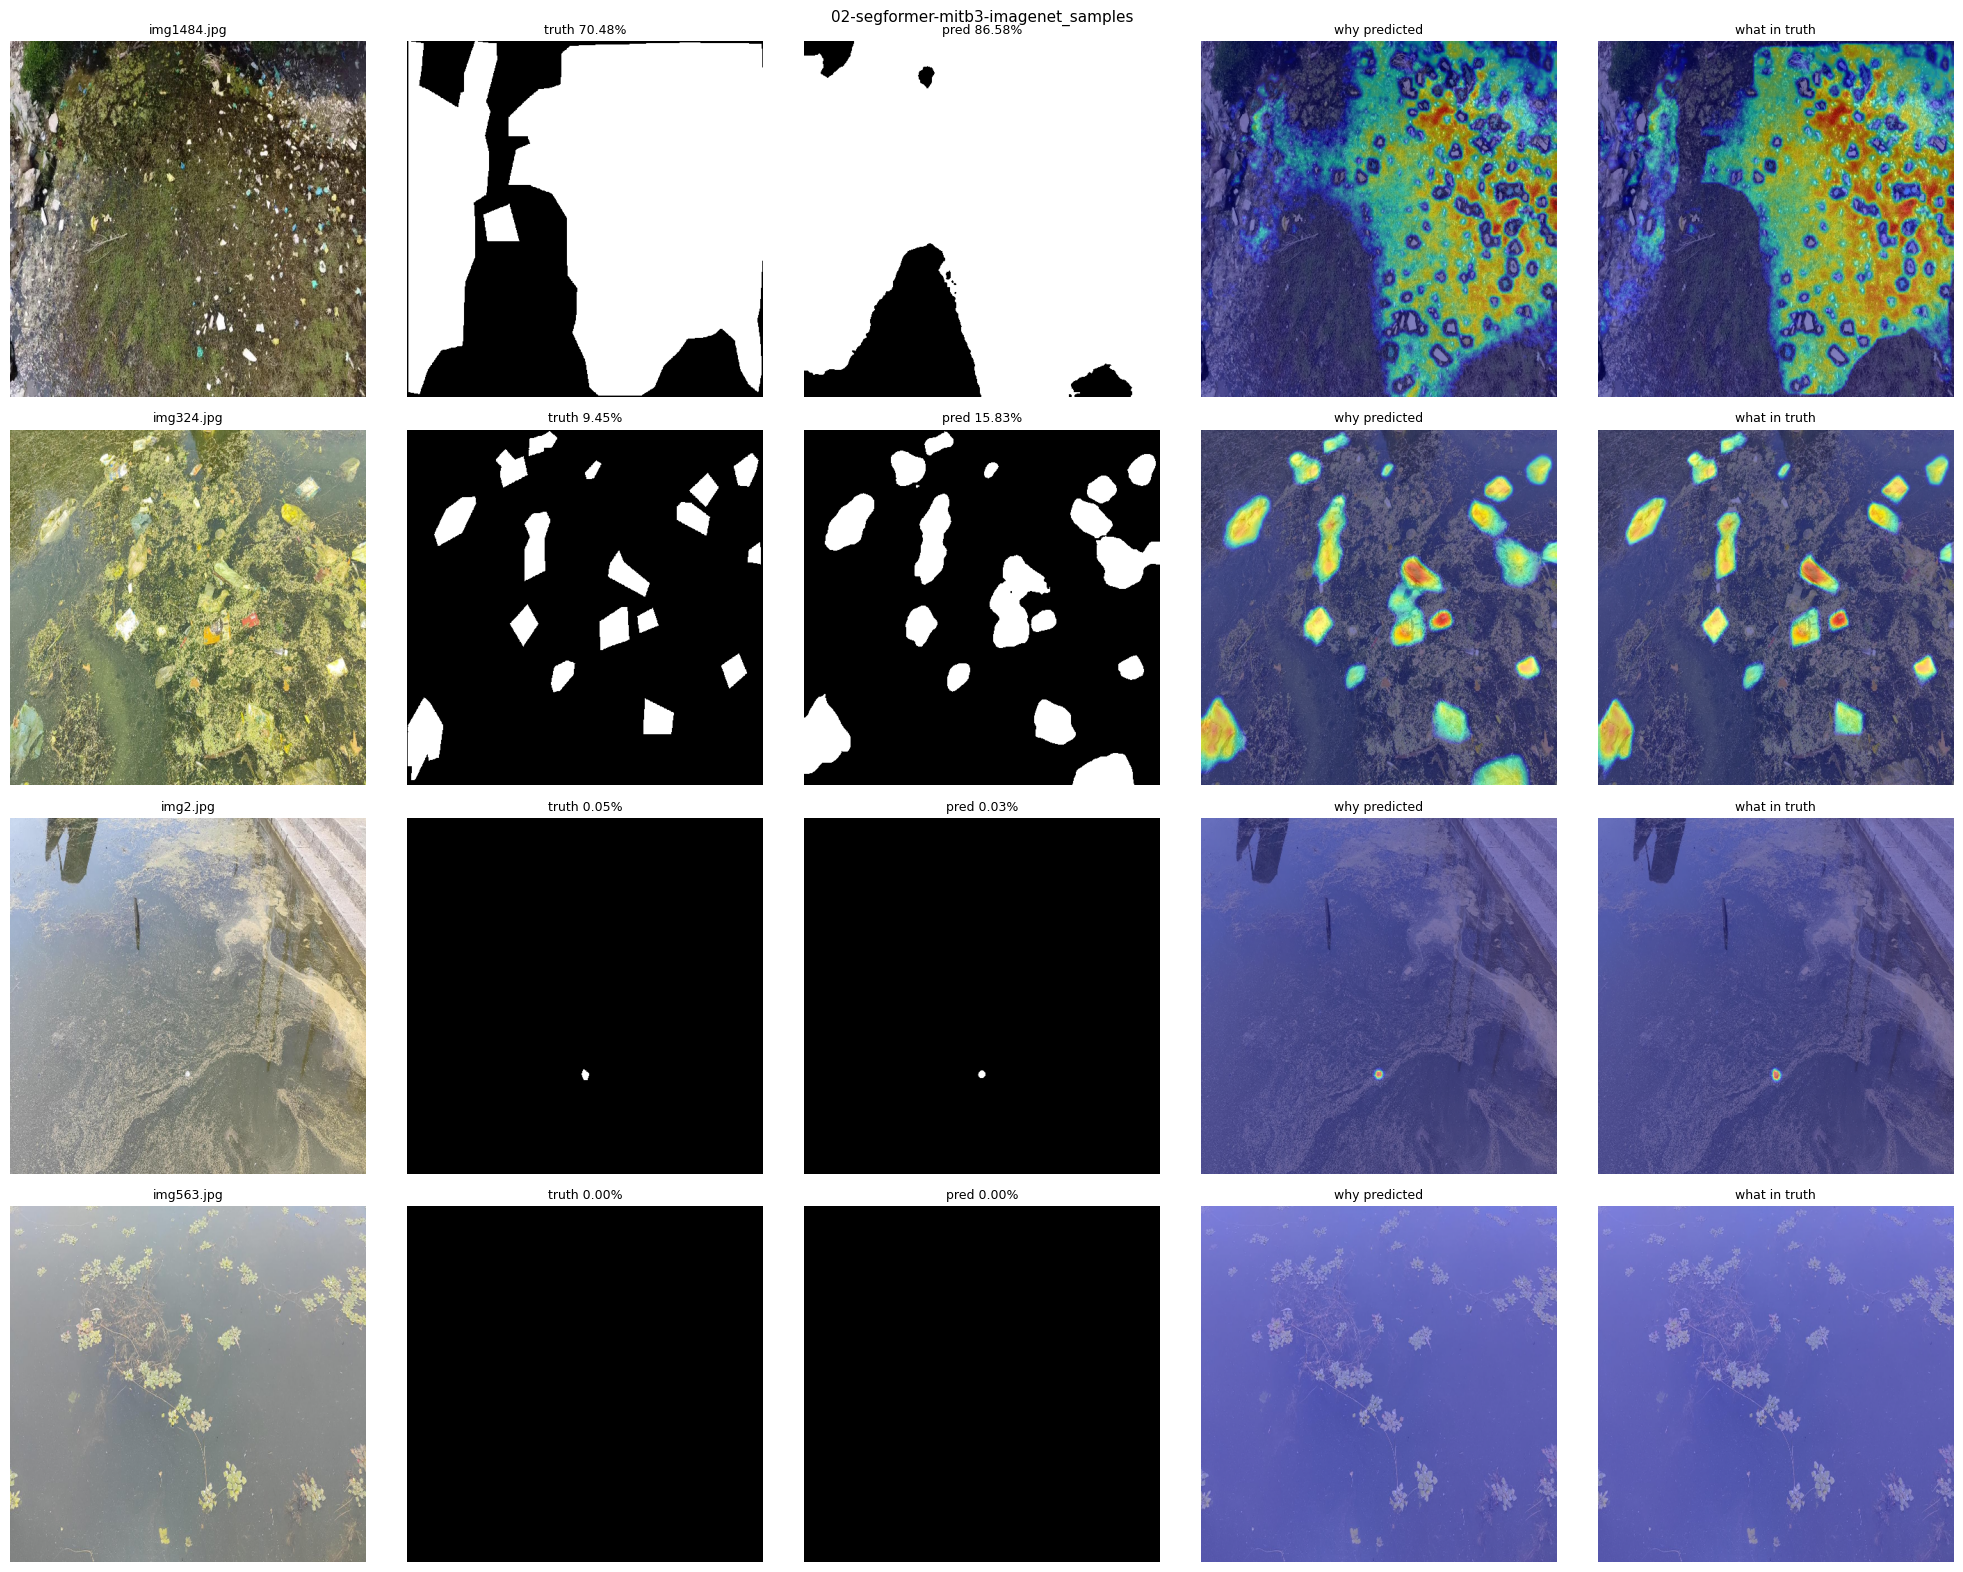

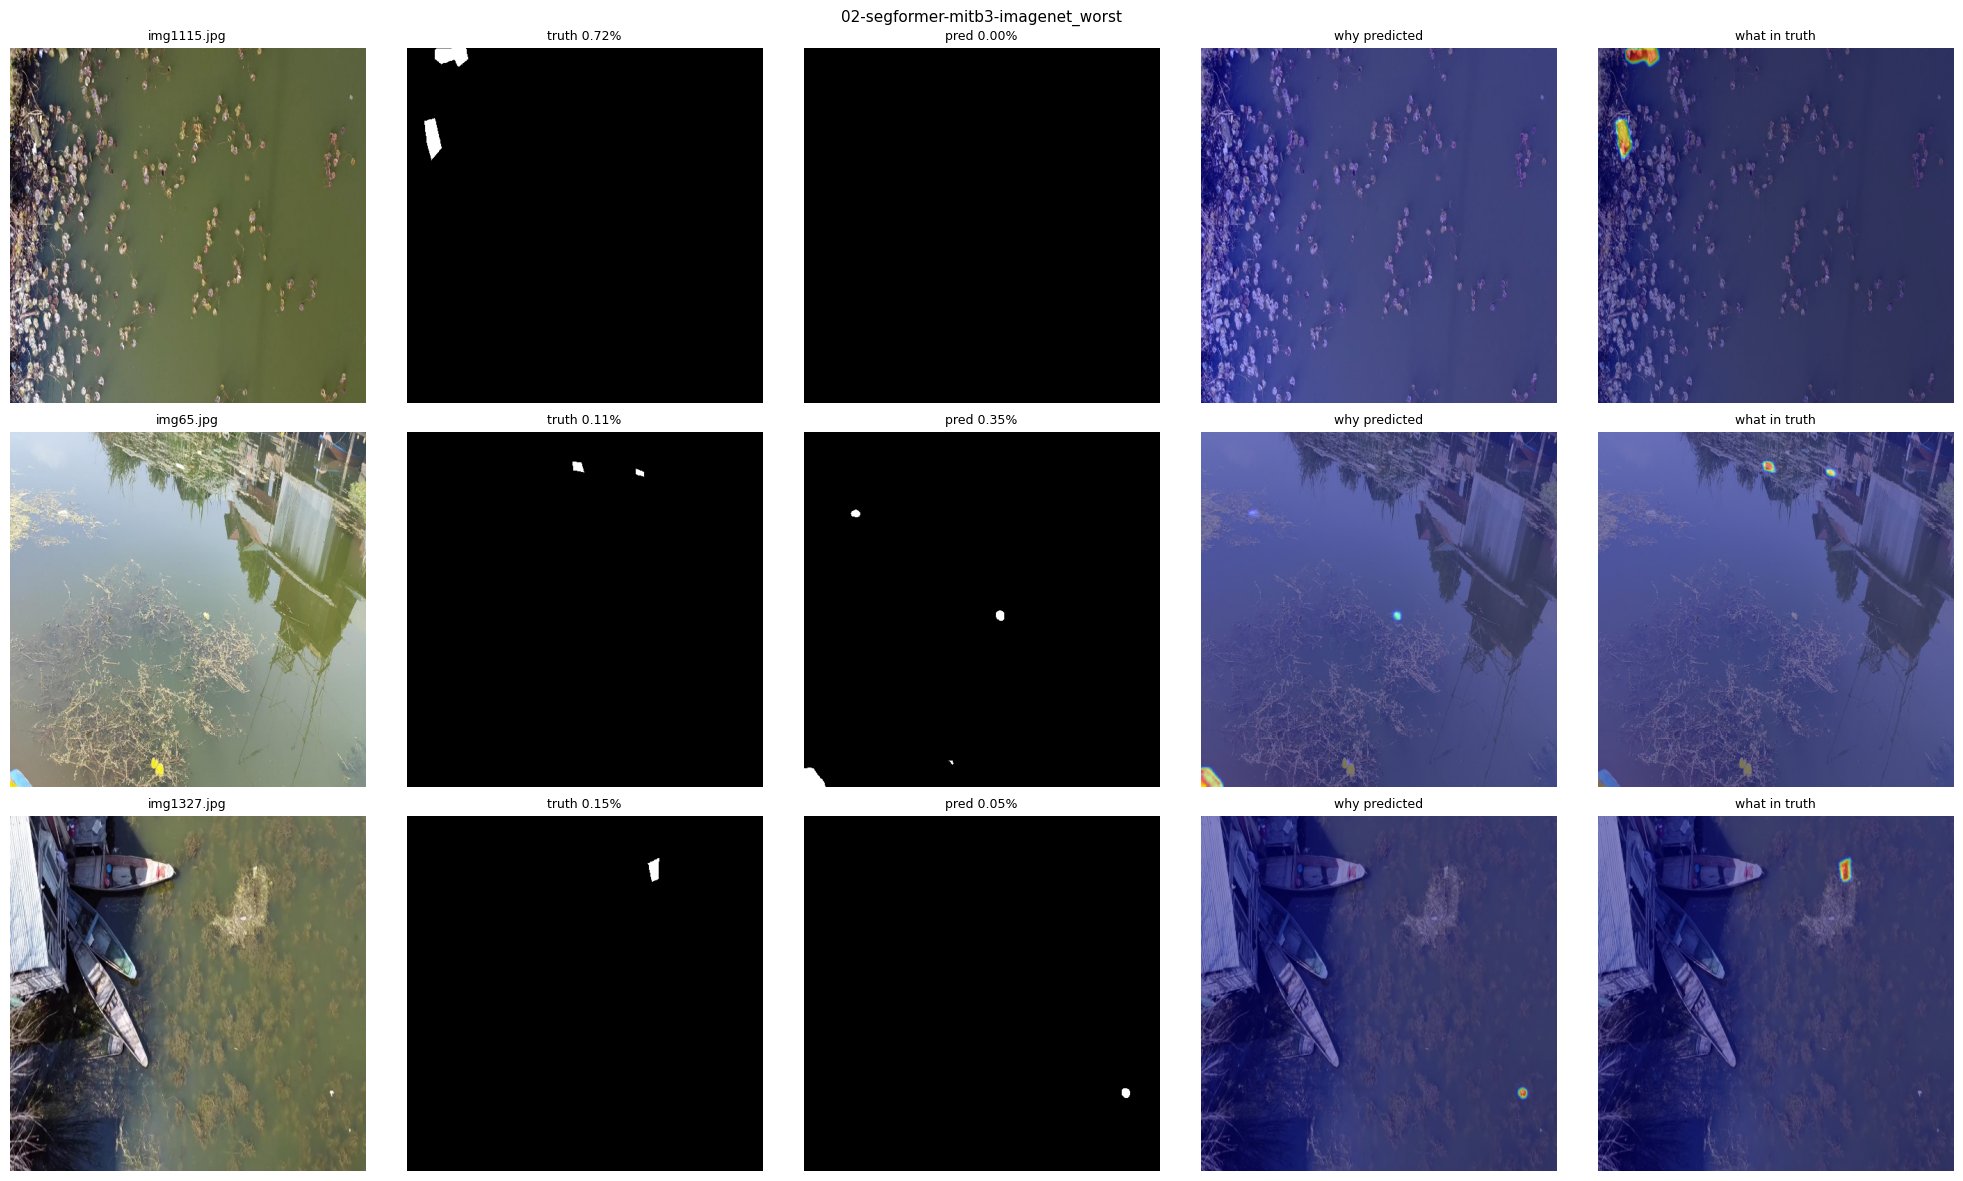

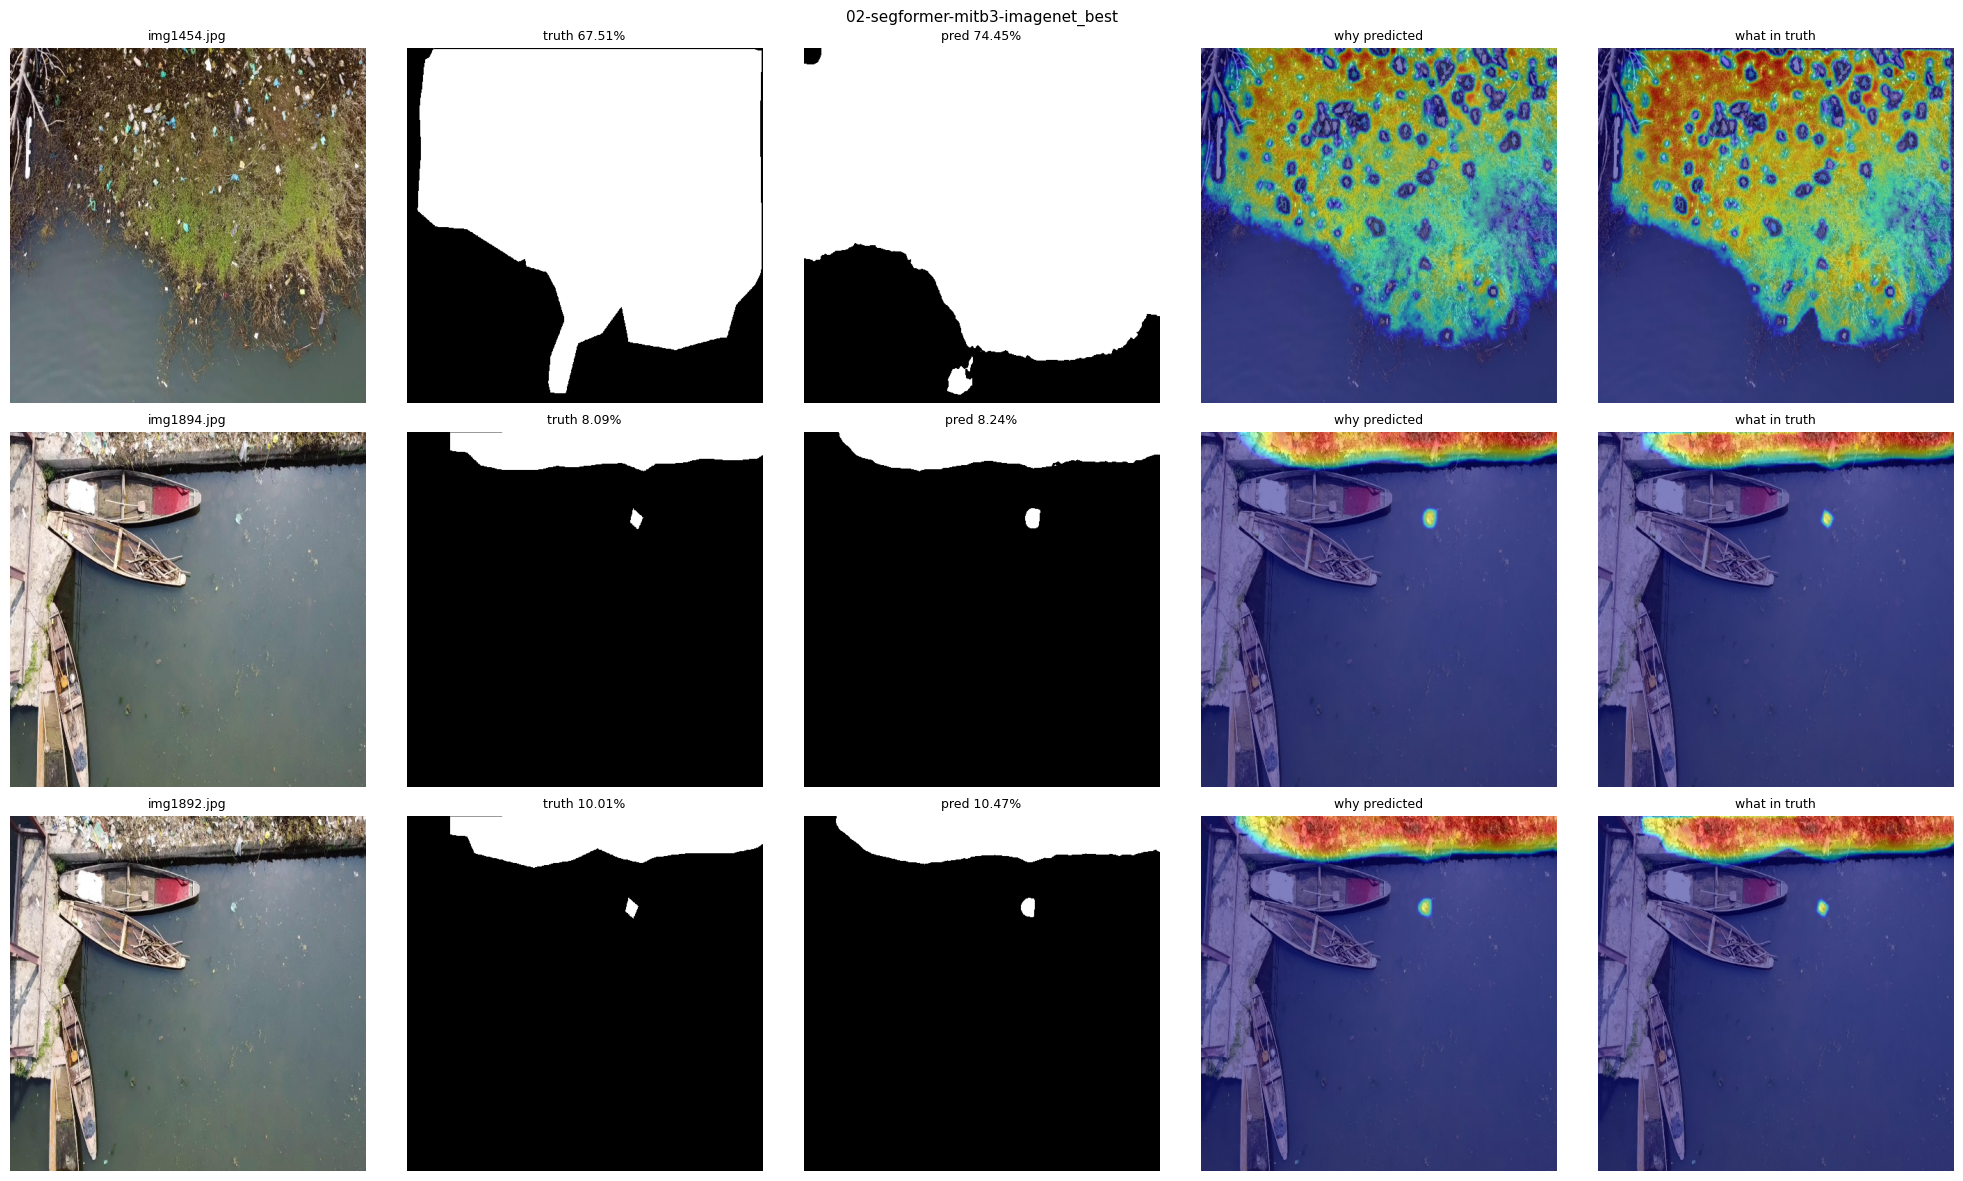

  saved → /content/PDIS-Net/xai/out/02-segformer-mitb3-imagenet


In [ ]:
ALL_RESULTS = []

for RUN in RUNS:
    print(f"\n{'='*60}\n{RUN}\n{'='*60}")

    run_dir, pth_file, metrics_path = resolve_run_paths(RUN)

    if run_dir is None or pth_file is None or metrics_path is None:
        print("  SKIP — weights or metrics not found")
        continue

    if pth_file.stat().st_size < 1e6:
        print("  SKIP — LFS pointer, not real weights")
        continue

    metrics = json.load(open(metrics_path))
    CFG = metrics["cfg"]
    arch = CFG["arch"]
    init = CFG["init"]
    backbone = CFG.get("backbone", "mit-b3")
    S = CFG["img_size"]
    thr = CFG.get("threshold", 0.5)

    print(f"  arch={arch} | backbone={backbone} | init={init} | mIoU={round(metrics['miou'], 4)}")

    _, test_df = train_test_split(df, test_size=0.15, random_state=CFG["seed"], stratify=df["has_plastic"])
    test_df = test_df.reset_index(drop=True)

    try:
        net = build_model(arch, backbone, init)
    except Exception as e:
        print(f"  SKIP — build failed: {e}")
        continue

    try:
        net.load_state_dict(torch.load(pth_file, map_location="cpu", weights_only=True))
    except Exception as e:
        print(f"  SKIP — load_state_dict failed: {e}")
        continue

    model = Logits(net).to(DEVICE).eval()

    try:
        layer = get_target_layer(net, arch)
    except Exception as e:
        print(f"  SKIP — layer error: {e}")
        del model, net
        torch.cuda.empty_cache()
        continue

    cam = SegEigenCAMLite(model, [layer])
    out_dir = XAI_OUT / RUN
    out_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    for _, r in test_df.iterrows():
        img, gt, x = load_image(r, S)
        pr = predict(model, x, thr)
        fg, bg = ious(pr, gt)
        rows.append({"image_name": r["image_name"], "fg_iou": fg,
                     "miou": (fg+bg)/2, "gt_pct": gt.mean()*100, "pred_pct": pr.mean()*100})

    per_img = pd.DataFrame(rows)
    reproduced = round(per_img["miou"].mean(), 4)
    per_img.to_csv(out_dir / "per_image.csv", index=False)
    print(f"  reproduced={reproduced} | original={round(metrics['miou'], 4)}")

    has = per_img[per_img.gt_pct > 0].sort_values("fg_iou")

    show_grid(SAMPLES, f"{RUN}_samples", df, model, cam, S, thr, out_dir)
    show_grid(list(has.image_name[:3]), f"{RUN}_worst", df, model, cam, S, thr, out_dir)
    show_grid(list(has.image_name[-3:]), f"{RUN}_best", df, model, cam, S, thr, out_dir)

    kept_hot, kept_cold = faithfulness(per_img, df, model, cam, S, thr)

    summary = {
        "run": RUN, "arch": arch, "backbone": backbone, "init": init,
        "test_miou": metrics["miou"], "reproduced_miou": reproduced,
        "n_faithfulness_images": len(kept_hot),
        "kept_after_hot_delete": float(np.mean(kept_hot)) if kept_hot else None,
        "kept_after_cold_delete": float(np.mean(kept_cold)) if kept_cold else None,
        "hot_hurts_more_in": int(sum(h < c for h, c in zip(kept_hot, kept_cold))),
    }
    json.dump(summary, open(out_dir / "xai_summary.json", "w"), indent=2)
    ALL_RESULTS.append(summary)
    print(f"  saved → {out_dir}")

    del model, net, cam
    torch.cuda.empty_cache()

In [ ]:
if not ALL_RESULTS:
    print("No results.")
else:
    summary_df = pd.DataFrame(ALL_RESULTS)
    summary_df.to_csv(XAI_OUT / "all_xai_summary.csv", index=False)
    cols = ["run", "arch", "backbone", "init", "test_miou", "reproduced_miou",
            "kept_after_hot_delete", "kept_after_cold_delete", "hot_hurts_more_in"]
    display(summary_df[cols].sort_values("test_miou", ascending=False).reset_index(drop=True))

,run,arch,backbone,init,test_miou,reproduced_miou,kept_after_hot_delete,kept_after_cold_delete,hot_hurts_more_in
0,02-segformer-mitb3-imagenet,segformer,mit-b3,imagenet,0.821019,0.821,0.127859,0.61049,198
